In [6]:
from typing import Set

from config.paths import DATASET_ROOT, EXTRACTED_ROOT
from data_labeling_pipeline.grandtour_missions import missions

grand_tour_folder = DATASET_ROOT
output_root = EXTRACTED_ROOT

# Configuration Flags
PROCESS_RHE_LABELS = False
PROCESS_SIMPLE_LABELS = True
SKIP_NONEMPTY_OUTPUT_DIRS = False

all_mission_short_names: Set[str] = set([m["short_name"] for m in missions])
mission_short_names_to_process: Set[str] = set(all_mission_short_names)
# Example subset:
# mission_short_names_to_process = {"LMB-1"}

missions_to_process = [
    mission
    for mission in missions
    if mission["short_name"] in mission_short_names_to_process
]


print(f"Configured {len(missions_to_process)} missions for processing.")
print(f"PROCESS_RHE_LABELS = {PROCESS_RHE_LABELS}")
print(f"PROCESS_SIMPLE_LABELS = {PROCESS_SIMPLE_LABELS}")
print(f"SKIP_NONEMPTY_OUTPUT_DIRS = {SKIP_NONEMPTY_OUTPUT_DIRS}")

Configured 49 missions for processing.
PROCESS_RHE_LABELS = False
PROCESS_SIMPLE_LABELS = True
SKIP_NONEMPTY_OUTPUT_DIRS = False


In [ ]:
import traceback

from data_labeling_pipeline import DataLabelingPipeline
from tqdm.notebook import tqdm

if PROCESS_SIMPLE_LABELS:
    from simple_baseline_labels import SimpleBaselineLabeler

processed_mission_outputs = []
erroneous_missions = []

for mission in tqdm(missions_to_process, desc="Processing missions", disable=None):
    mission_short_name = mission["short_name"]
    mission_path = grand_tour_folder / "ros1" / mission_short_name
    if not mission_path.exists():
        print(f"Skipping {mission_short_name}: missing {mission_path}")
        continue

    mission_output_dir = output_root / mission_short_name

    # Determine what needs processing
    rhe_needed = PROCESS_RHE_LABELS and not (
        SKIP_NONEMPTY_OUTPUT_DIRS
        and mission_output_dir.exists()
        and (mission_output_dir / "trav_labels.npy").exists()
    )
    simple_needed = PROCESS_SIMPLE_LABELS and not (
        SKIP_NONEMPTY_OUTPUT_DIRS
        and mission_output_dir.exists()
        and (mission_output_dir / "simple_trav_lin.npy").exists()
    )

    # Skip if everything is already done
    if not rhe_needed and not simple_needed:
        if SKIP_NONEMPTY_OUTPUT_DIRS and mission_output_dir.exists():
            print(f"Skipping {mission_short_name}: Output dir is nonempty")
        continue

    print(f"Processing {mission_short_name} -> {mission_output_dir}")

    # Process RHE labels
    if rhe_needed:
        pipeline = DataLabelingPipeline(mission_path=mission_path)
        try:
            pipeline.process_mission(output_dir=mission_output_dir)
            processed_mission_outputs.append({
                "mission": mission,
                "mission_path": mission_path,
                "output_dir": mission_output_dir,
            })
        except Exception as e:
            print(f"Error processing {mission_short_name} (RHE): {e}")
            erroneous_missions.append((mission, "RHE", e))

    # Process simple labels
    if simple_needed:
        labeler = SimpleBaselineLabeler(mission_path=mission_path)
        try:
            labeler.process_mission(output_dir=mission_output_dir)
        except Exception as e:
            print(traceback.format_exc())
            erroneous_missions.append((mission, "simple", e))

print(f"Processed {len(processed_mission_outputs)} missions (RHE).")

if erroneous_missions:
    print("\nErroneous missions:")
    for mission, label_type, error in erroneous_missions:
        print(f"- {mission['short_name']} [{label_type}]: {error}")

Processing missions:   0%|          | 0/49 [00:00<?, ?it/s]

Processing ETH-1 -> output/ETH-1


Median dt: 0.050s, regular diffs: 5160/5190
Simple baseline labels saved to output/ETH-1
Processing ETH-2 -> output/ETH-2
Median dt: 0.050s, regular diffs: 5715/5738
Traceback (most recent call last):
  File "/tmp/ipykernel_245829/66846005.py", line 60, in <module>
    labeler.process_mission(output_dir=mission_output_dir)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/workspaces/master-thesis-lmertens/data_labeling_pipeline/src/simple_baseline_labels/labeling.py", line 112, in process_mission
    shared_ts, U, Z = self.loader.load_data_shared_timestamps(
                      ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        dt=self.dt, include_lateral_command=True
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/workspaces/master-thesis-lmertens/data_labeling_pipeline/src/data_labeling_pipeline/dataset_loader.py", line 275, in load_data_shared_timestamps
    odom_ts, odom_pos, odom_orien, odom_linear, odom_angular = self.load_odometry()
      

Median dt: 0.050s, regular diffs: 5160/5190


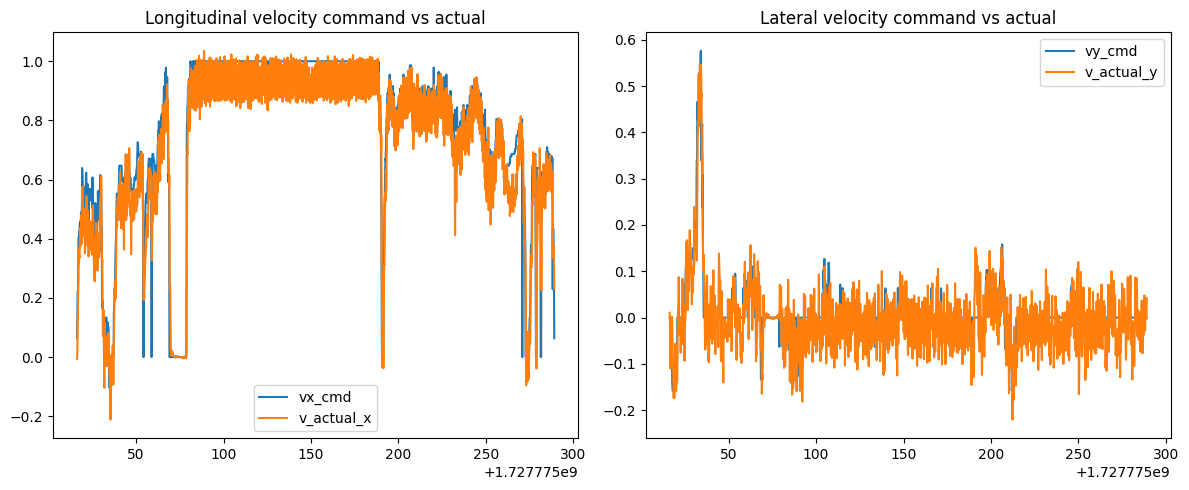

In [11]:
# Debug simple labels

from data_labeling_pipeline.dataset_loader import GrandTourLoader
from simple_baseline_labels.labeling import _body_frame_velocities

loader = GrandTourLoader(grand_tour_folder / "ros1" / "ETH-1")
dt = 0.1

shared_ts, U, Z = loader.load_data_shared_timestamps(
    dt=dt, include_lateral_command=True
)

vx_cmd = U[:, 0]
vy_cmd = U[:, 1]
omega_cmd = U[:, 2]

px = Z[:, 0]
py = Z[:, 1]
yaw = Z[:, 2]

v_actual_x, v_actual_y, omega_actual = _body_frame_velocities(px, py, yaw, dt)


# Plot vx_cmd vs v_actual_x and vy_cmd vs v_actual_y to check if they look reasonable.
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(shared_ts, vx_cmd, label="vx_cmd")
plt.plot(shared_ts, v_actual_x, label="v_actual_x")
plt.legend()
plt.title("Longitudinal velocity command vs actual")
plt.subplot(1, 2, 2)
plt.plot(shared_ts, vy_cmd, label="vy_cmd")
plt.plot(shared_ts, v_actual_y, label="v_actual_y")
plt.legend()
plt.title("Lateral velocity command vs actual")
plt.tight_layout()
plt.show()

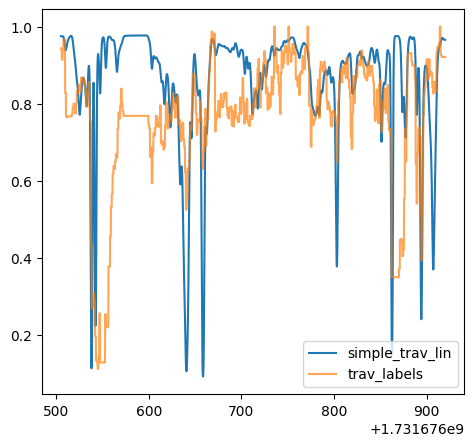

In [12]:
import numpy as np

output_folder = output_root / "LMB-1"

# Plot the following:
# np.save(out_path / "timestamp.npy", shared_ts)
# vs
# np.save(out_path / "simple_v_error_lin_raw.npy", v_err_lin_raw)
# np.save(out_path / "simple_v_error_ang_raw.npy", v_err_ang_raw)

# np.save(out_path / "simple_v_error_lin.npy", v_err_lin)
# np.save(out_path / "simple_v_error_ang.npy", v_err_ang)

# np.save(out_path / "simple_trav_lin.npy", tau_lin)
# np.save(out_path / "simple_trav_ang.npy", tau_ang)


# Read simple_trav_lin.npy and trav_labels.npy and plot them
shared_ts = np.load(output_folder / "timestamp.npy")
simple_trav_lin = np.load(output_folder / "simple_trav_lin.npy")
trav_labels = np.load(output_folder / "trav_labels.npy")[:, 0]
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(shared_ts, simple_trav_lin, label="simple_trav_lin")
plt.plot(shared_ts, trav_labels, label="trav_labels", alpha=0.7)
plt.legend()

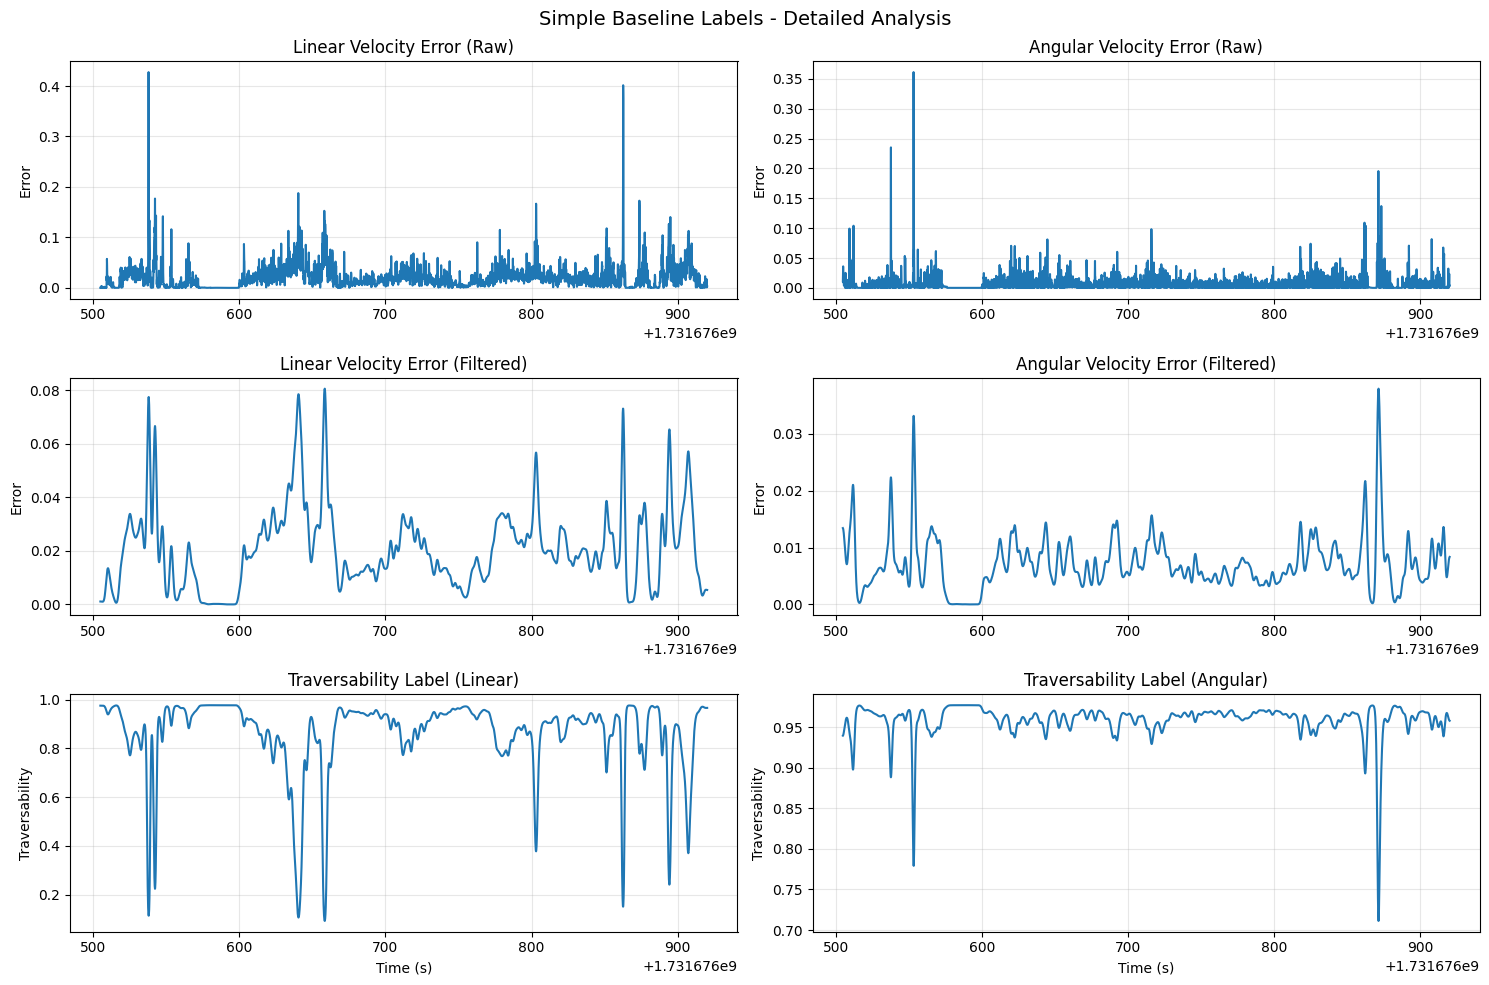

In [13]:
# Plot the saved data
shared_ts = np.load(output_folder / "timestamp.npy")
simple_v_error_lin_raw = np.load(output_folder / "simple_v_error_lin_raw.npy")
simple_v_error_ang_raw = np.load(output_folder / "simple_v_error_ang_raw.npy")
simple_v_error_lin = np.load(output_folder / "simple_v_error_lin.npy")
simple_v_error_ang = np.load(output_folder / "simple_v_error_ang.npy")
simple_trav_lin = np.load(output_folder / "simple_trav_lin.npy")
simple_trav_ang = np.load(output_folder / "simple_trav_ang.npy")

# Create subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 10))
fig.suptitle("Simple Baseline Labels - Detailed Analysis", fontsize=14)

# Row 1: Velocity errors raw
axes[0, 0].plot(shared_ts, simple_v_error_lin_raw)
axes[0, 0].set_title("Linear Velocity Error (Raw)")
axes[0, 0].set_ylabel("Error")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(shared_ts, simple_v_error_ang_raw)
axes[0, 1].set_title("Angular Velocity Error (Raw)")
axes[0, 1].set_ylabel("Error")
axes[0, 1].grid(True, alpha=0.3)

# Row 2: Velocity errors filtered
axes[1, 0].plot(shared_ts, simple_v_error_lin)
axes[1, 0].set_title("Linear Velocity Error (Filtered)")
axes[1, 0].set_ylabel("Error")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(shared_ts, simple_v_error_ang)
axes[1, 1].set_title("Angular Velocity Error (Filtered)")
axes[1, 1].set_ylabel("Error")
axes[1, 1].grid(True, alpha=0.3)

# Row 3: Traversability labels
axes[2, 0].plot(shared_ts, simple_trav_lin)
axes[2, 0].set_title("Traversability Label (Linear)")
axes[2, 0].set_ylabel("Traversability")
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(shared_ts, simple_trav_ang)
axes[2, 1].set_title("Traversability Label (Angular)")
axes[2, 1].set_ylabel("Traversability")
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()